<a href="https://colab.research.google.com/github/Nayeem-294/CNN-Group09-Pneumonia-Detection/blob/main/CNN_Group09_Submission2_ResNet50_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Project - Submission 2: Pretrained model ResNet50, with and without fine-tuning
**Project:** Pneumonia Detection from Chest X-Ray Images Using Convolutional Neural Networks

**Group No:** 09

| Name | Student ID |
|---|---|
| Nayeem Ahmed | 2024-1-60-294 |
| Mahbuba Hoque Tabassum | 2023-2-60-030 |
| Sharmin Zaman Setu | 2023-3-60-476 |
| SM Erbajul Hasan | 2023-3-60-010 |

**This notebook:** ResNet50(ImageNet-pretrained) trained in two modes on the Kermany chest X-ray dataset:
1. **Without fine-tuning:** the pretrained part is frozen, only the new classifier head is trained.
2. **With fine-tuning:** the top 40% of the pretrained layers are also trained, with a small learning rate.

Each mode is trained for **40 epochs**. MobileNetV2 is used by Kundu et al. (2021) and Cha et al. (2021) in our related work.

Required results for each mode: accuracy curve, loss curve, classification report, confusion matrix on the test set, plus accuracy / precision / recall / F1 and training and testing time.



## 1. Setup

In [1]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "NO GPU found - use Runtime > Change runtime type > T4 GPU (CPU will be very slow)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os, sys, time, json, subprocess
from pathlib import Path

# Download the dataset from Kaggle (same as Submission 1). Skipped if it is already there.
if not Path("chest_xray_data").exists():
    from google.colab import files
    print("Upload your kaggle.json file:")
    up = files.upload()

    # Dynamically find the key in case Colab renamed the uploaded file (e.g., to 'kaggle (1).json')
    uploaded_filename = None
    for filename in up.keys():
        if "kaggle" in filename.lower() and filename.lower().endswith(".json"):
            uploaded_filename = filename
            break

    if not uploaded_filename:
         raise FileNotFoundError("Could not find a valid kaggle.json file in your uploads.")

    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    with open(os.path.expanduser("~/.kaggle/kaggle.json"), "wb") as f:
        f.write(up[uploaded_filename])
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "paultimothymooney/chest-xray-pneumonia",
                    "-p", "chest_xray_data", "--unzip"], check=True)

def find_root(base="chest_xray_data"):
    for p in Path(base).rglob("train"):
        if p.is_dir() and (p.parent / "test").is_dir() and "__MACOSX" not in str(p):
            return p.parent
    raise FileNotFoundError("Could not find train/test folders")

DATA_DIR = find_root()
print("Dataset root:", DATA_DIR)

Upload your kaggle.json file:


Saving kaggle (1).json to kaggle (1).json
Dataset root: chest_xray_data/chest_xray


In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support, roc_auc_score)
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# ---- Settings ----
MODEL_NAME = "ResNet50"
APP = tf.keras.applications.ResNet50
PREPROCESS = tf.keras.applications.resnet50.preprocess_input

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 40            # 40 epochs
VAL_FRACTION = 0.15    # validation taken from the train folder
WEIGHTS = "imagenet"
FT_FRACTION = 0.4      # share of the top layers that are unfrozen in the fine-tuning mode
LR_FROZEN = 1e-3
LR_FINETUNE = 1e-4
CLASSES = ["NORMAL", "PNEUMONIA"]   # label 0 = NORMAL, label 1 = PNEUMONIA (positive class)

tf.keras.utils.set_random_seed(SEED)

## 2. Data preparation
- The original `val` folder has only 16 images, so it is **not used**. We take a **stratified 15%** of the training images as the validation set.
- The original **test** folder (624 images) is used **only for the final evaluation**, never for tuning.
- Images are resized to 224x224 and converted to 3 channels (grayscale images are copied to RGB).
- **Class weights** handle the imbalance (about 3 PNEUMONIA images for every NORMAL image).
- **Augmentation** (training only): horizontal flip, small rotation, zoom, shift and brightness change.

In [4]:
def collect(split):
    paths, labels = [], []
    for li, c in enumerate(CLASSES):
        for p in sorted((DATA_DIR / split / c).rglob("*")):
            if p.suffix.lower() in {".jpeg", ".jpg", ".png"}:
                paths.append(str(p)); labels.append(li)
    return np.array(paths), np.array(labels)

all_p, all_y = collect("train")
te_p, te_y = collect("test")
tr_p, va_p, tr_y, va_y = train_test_split(all_p, all_y, test_size=VAL_FRACTION,
                                          stratify=all_y, random_state=SEED)

summary = pd.DataFrame({s: {c: int((y == i).sum()) for i, c in enumerate(CLASSES)}
                        for s, y in [("train", tr_y), ("validation", va_y), ("test", te_y)]})
summary["total"] = summary.sum(axis=1)
summary.loc["TOTAL"] = summary.sum()
display(summary)

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=tr_y)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print("Class weights:", {CLASSES[k]: round(v, 3) for k, v in class_weight.items()})

,train,validation,test,total
NORMAL,1140,201,234,1575
PNEUMONIA,3293,582,390,4265
TOTAL,4433,783,624,5840


Class weights: {'NORMAL': 1.944, 'PNEUMONIA': 0.673}


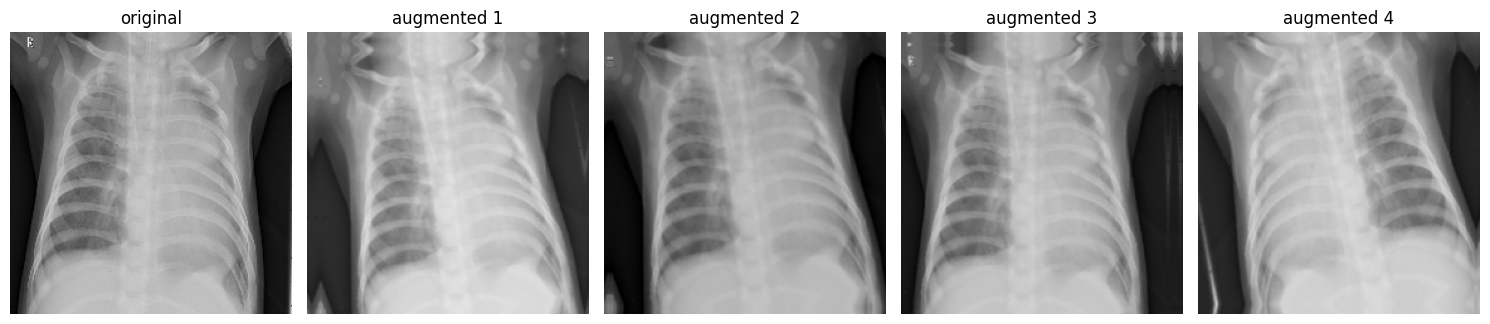

In [5]:
def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)          # grayscale -> 3 channels
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))     # pixel range stays 0-255 here
    return img, tf.expand_dims(tf.cast(label, tf.float32), -1)

def make_ds(p, y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if shuffle:
        ds = ds.shuffle(len(p), seed=SEED)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(tr_p, tr_y, True)
val_ds = make_ds(va_p, va_y, False)
test_ds = make_ds(te_p, te_y, False)

def make_augment():
    return models.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.03),                 # about +-11 degrees
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomBrightness(0.1, value_range=(0, 255)),
    ], name="augmentation")

augment = make_augment()

# Show what augmentation does to one training image
img0, _ = next(iter(train_ds.unbatch().take(1)))
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(img0.numpy().astype("uint8")); axes[0].set_title("original")
for k in range(1, 5):
    axes[k].imshow(augment(tf.expand_dims(img0, 0), training=True)[0].numpy().astype("uint8"))
    axes[k].set_title(f"augmented {k}")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Model
ResNet50 (ImageNet weights) + global average pooling + dropout 0.3 + one sigmoid unit.

- BatchNorm layers inside ResNet50 always stay in inference mode, which is the standard safe way to fine-tune.
- The same augmentation, class weights, optimiser (Adam) and 40 epochs are used in both modes, so the only difference is **frozen vs fine-tuned**.
- The weights of the **epoch with the lowest validation loss** are restored before testing (this guards against overfitting in the later epochs), and the learning rate is cut when the validation loss stops improving.

In [6]:
def build_model(finetune):
    base = APP(include_top=False, weights=WEIGHTS, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    if finetune:
        base.trainable = True
        n_unfreeze = int(len(base.layers) * FT_FRACTION)
        for l in base.layers[:-n_unfreeze]:
            l.trainable = False
        for l in base.layers[-n_unfreeze:]:
            if isinstance(l, layers.BatchNormalization):
                l.trainable = False
        lr = LR_FINETUNE
    else:
        base.trainable = False
        lr = LR_FROZEN
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augment()(inputs)
    x = layers.Lambda(PREPROCESS, name="preprocess")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inputs, out, name=f"{MODEL_NAME}_{'finetuned' if finetune else 'frozen'}")
    model.compile(optimizer=Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    n_train = int(np.sum([np.prod(w.shape) for w in model.trainable_weights]))
    print(f"{model.name}: learning rate {lr}, trainable parameters {n_train:,}")
    return model

def run_mode(finetune):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(finetune)
    tag = "finetuned" if finetune else "frozen"
    ckpt = f"best_{MODEL_NAME}_{tag}.weights.h5"
    cbs = [ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, save_weights_only=True),
           ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                     class_weight=class_weight, callbacks=cbs, verbose=2)
    train_time = time.time() - t0
    model.load_weights(ckpt)                      # best validation epoch
    model.predict(test_ds.take(1), verbose=0)     # warm-up so test time is not distorted
    t0 = time.time()
    probs = model.predict(test_ds, verbose=0).ravel()
    test_time = time.time() - t0
    return hist.history, probs, train_time, test_time

def report(title, history, probs, train_time, test_time):
    y_true = te_y
    y_pred = (probs >= 0.5).astype(int)
    epochs = range(1, len(history["loss"]) + 1)
    best = int(np.argmin(history["val_loss"]))

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(epochs, history["accuracy"], label="train")
    ax[0].plot(epochs, history["val_accuracy"], label="validation")
    ax[0].axvline(best + 1, ls="--", color="grey", label=f"best epoch ({best + 1})")
    ax[0].set_title(f"{title}: accuracy"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("accuracy"); ax[0].legend()
    ax[1].plot(epochs, history["loss"], label="train")
    ax[1].plot(epochs, history["val_loss"], label="validation")
    ax[1].axvline(best + 1, ls="--", color="grey", label=f"best epoch ({best + 1})")
    ax[1].set_title(f"{title}: loss"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("loss"); ax[1].legend()
    plt.tight_layout(); plt.show()

    print(f"Classification report - {title} (test set, {len(y_true)} images)")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4.6, 4))
    plt.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    plt.xticks([0, 1], CLASSES); plt.yticks([0, 1], CLASSES)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix - {title}")
    plt.tight_layout(); plt.show()

    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1)
    tr_acc, va_acc = history["accuracy"][best], history["val_accuracy"][best]
    gap = tr_acc - va_acc
    if gap > 0.05:
        diag = f"possible OVERFITTING (train accuracy {tr_acc:.3f} is {gap:.3f} above validation {va_acc:.3f})"
    elif tr_acc < 0.85 and va_acc < 0.85:
        diag = f"possible UNDERFITTING (train {tr_acc:.3f}, validation {va_acc:.3f} are both low)"
    else:
        diag = f"no strong sign of over- or underfitting (train {tr_acc:.3f}, validation {va_acc:.3f})"
    print("Fit check at the best epoch:", diag)
    print(f"Training time: {train_time:.1f} s ({train_time / 60:.1f} min) | Testing time: {test_time:.2f} s")

    return dict(model=MODEL_NAME, mode=title, epochs_run=len(epochs), best_epoch=best + 1,
                train_acc=round(tr_acc, 4), val_acc=round(va_acc, 4),
                test_accuracy=round(accuracy_score(y_true, y_pred), 4),
                precision=round(p, 4), recall=round(r, 4), f1=round(f, 4),
                auc=round(roc_auc_score(y_true, probs), 4),
                train_time_s=round(train_time, 1), test_time_s=round(test_time, 2))

## 4. Mode A: MobileNetV2 WITHOUT fine-tuning
All pretrained layers are frozen. Only the new classifier head is trained (learning rate 1e-3).

In [7]:
hist_a, probs_a, tt_a, ts_a = run_mode(finetune=False)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
ResNet50_frozen: learning rate 0.001, trainable parameters 2,049
Epoch 1/40
139/139 - 66s - 477ms/step - accuracy: 0.8637 - loss: 0.3010 - val_accuracy: 0.9502 - val_loss: 0.1262 - learning_rate: 0.0010
Epoch 2/40
139/139 - 63s - 455ms/step - accuracy: 0.9316 - loss: 0.1737 - val_accuracy: 0.9476 - val_loss: 0.1297 - learning_rate: 0.0010
Epoch 3/40
139/139 - 34s - 247ms/step - accuracy: 0.9429 - loss: 0.1445 - val_accuracy: 0.9655 - val_loss: 0.0889 - learning_rate: 0.0010
Epoch 4/40
139/139 - 32s - 232ms/step - accuracy: 0.9481 - loss: 0.1256 - val_accuracy: 0.9195 - val_loss: 0.1862 - learning_rate: 0.0010
Epoch 5/40
139/139 - 33s - 239ms/step - accuracy: 0.9524 - loss: 0.1176 - val_accuracy: 0.9361 - val_loss: 0.1452 - learning_rate: 0.0010
Epoch 6/40

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
139/139 - 41s - 294ms/step - accuracy: 0.9567 - loss: 0.1166 - val_accuracy: 0.9361 - val_loss: 0.1403 - l

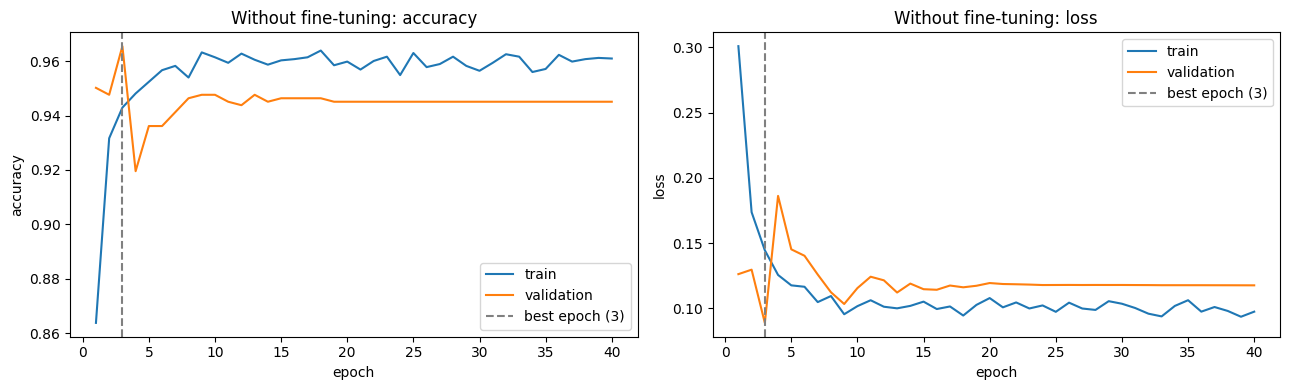

Classification report - Without fine-tuning (test set, 624 images)
              precision    recall  f1-score   support

      NORMAL     0.9426    0.4915    0.6461       234
   PNEUMONIA     0.7629    0.9821    0.8587       390

    accuracy                         0.7981       624
   macro avg     0.8528    0.7368    0.7524       624
weighted avg     0.8303    0.7981    0.7790       624



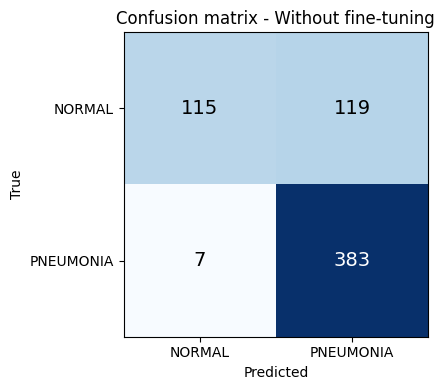

Fit check at the best epoch: no strong sign of over- or underfitting (train 0.943, validation 0.966)
Training time: 1514.0 s (25.2 min) | Testing time: 6.49 s


In [8]:
res_a = report("Without fine-tuning", hist_a, probs_a, tt_a, ts_a)

## 5. Mode B: ResNet50 WITH fine-tuning
The top 40% of the ResNet50 layers (except BatchNorm) are unfrozen and trained together with the head, using a small learning rate (1e-4).



In [12]:
hist_b, probs_b, tt_b, ts_b = run_mode(finetune=True)

ResNet50_finetuned: learning rate 0.0001, trainable parameters 19,155,713
Epoch 1/40
139/139 - 51s - 370ms/step - accuracy: 0.9163 - loss: 0.2061 - val_accuracy: 0.9617 - val_loss: 0.0918 - learning_rate: 1.0000e-04
Epoch 2/40
139/139 - 41s - 293ms/step - accuracy: 0.9704 - loss: 0.0815 - val_accuracy: 0.8761 - val_loss: 0.3259 - learning_rate: 1.0000e-04
Epoch 3/40
139/139 - 41s - 292ms/step - accuracy: 0.9716 - loss: 0.0783 - val_accuracy: 0.9195 - val_loss: 0.2113 - learning_rate: 1.0000e-04
Epoch 4/40

Epoch 4: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
139/139 - 41s - 292ms/step - accuracy: 0.9777 - loss: 0.0662 - val_accuracy: 0.9310 - val_loss: 0.2288 - learning_rate: 1.0000e-04
Epoch 5/40
139/139 - 36s - 262ms/step - accuracy: 0.9840 - loss: 0.0374 - val_accuracy: 0.9080 - val_loss: 0.3154 - learning_rate: 3.0000e-05
Epoch 6/40
139/139 - 35s - 254ms/step - accuracy: 0.9865 - loss: 0.0351 - val_accuracy: 0.9336 - val_loss: 0.1925 - learning_rate: 3.0000e

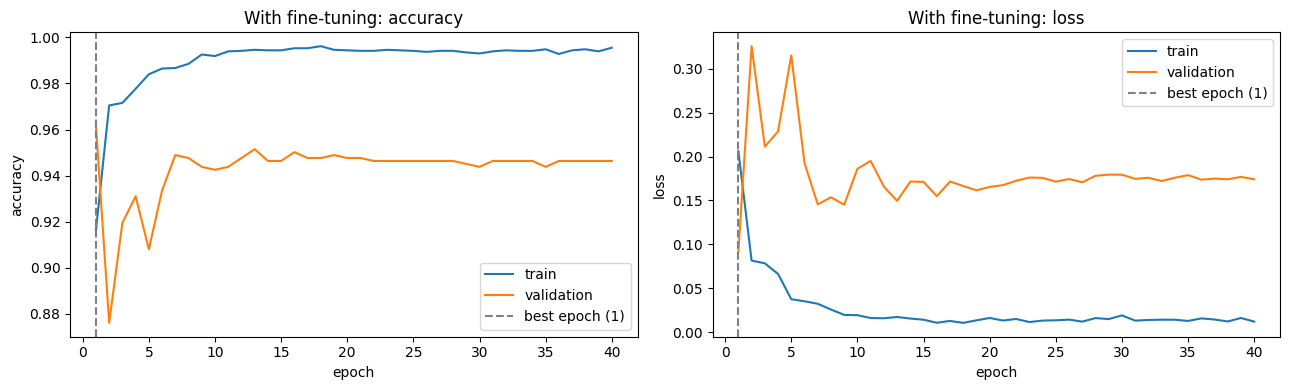

Classification report - With fine-tuning (test set, 624 images)
              precision    recall  f1-score   support

      NORMAL     0.9737    0.6325    0.7668       234
   PNEUMONIA     0.8178    0.9897    0.8956       390

    accuracy                         0.8558       624
   macro avg     0.8957    0.8111    0.8312       624
weighted avg     0.8763    0.8558    0.8473       624



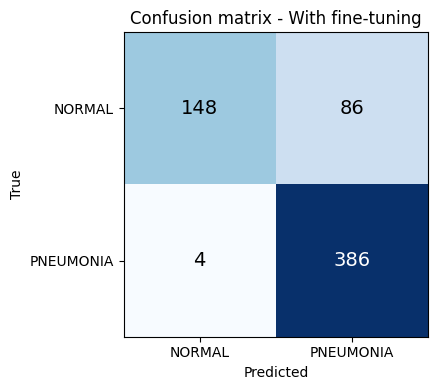

Fit check at the best epoch: no strong sign of over- or underfitting (train 0.916, validation 0.962)
Training time: 1565.6 s (26.1 min) | Testing time: 5.60 s


In [13]:
res_b = report("With fine-tuning", hist_b, probs_b, tt_b, ts_b)

## 6. Summary of both modes

mode,Without fine-tuning,With fine-tuning
model,ResNet50,ResNet50
epochs_run,40,40
best_epoch,3,1
train_acc,0.9429,0.9163
val_acc,0.9655,0.9617
test_accuracy,0.7981,0.8558
precision,0.7629,0.8178
recall,0.9821,0.9897
f1,0.8587,0.8956
auc,0.9456,0.9637


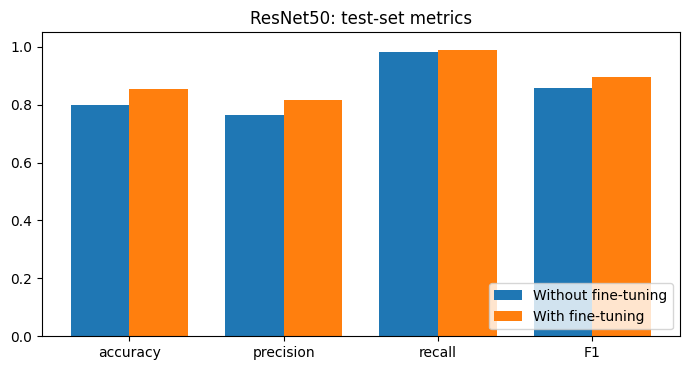

In [15]:
results = pd.DataFrame([res_a, res_b]).set_index("mode")
display(results.T)
results.to_csv(f"results_{MODEL_NAME}.csv")

fig, ax = plt.subplots(figsize=(7, 3.8))
metrics = ["test_accuracy", "precision", "recall", "f1"]
x = np.arange(len(metrics)); w = 0.38
ax.bar(x - w / 2, results.loc["Without fine-tuning", metrics], w, label="Without fine-tuning")
ax.bar(x + w / 2, results.loc["With fine-tuning", metrics], w, label="With fine-tuning")
ax.set_xticks(x); ax.set_xticklabels(["accuracy", "precision", "recall", "F1"])
ax.set_ylim(0, 1.05); ax.set_title(f"{MODEL_NAME}: test-set metrics"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### How overfitting and underfitting were handled
- **Dropout (0.3)** before the output layer and **data augmentation** during training.
- **Class weights**, so the model does not just predict the majority class (PNEUMONIA).
- **Best-epoch checkpoint:** the weights with the lowest validation loss are restored, so extra epochs that overfit do not hurt the test result.
- **Learning-rate reduction** when the validation loss stops improving.
- **Small learning rate (1e-4) and frozen BatchNorm** in the fine-tuning mode, so the pretrained features are not destroyed.
- The **fit check** printed after each mode compares train and validation accuracy at the best epoch.

## Observations: ResNet50

**Setup.** ResNet50 (ImageNet weights) was trained for 40 epochs in both modes on the same split, with the best-validation-loss weights restored for testing.

**Results on the test set (624 images)**

| Metric | Without fine-tuning | With fine-tuning |
|---|---|---|
| Accuracy | 0.7981 | 0.8558 |
| Precision | 0.7629 | 0.8178 |
| Recall | 0.9821 | 0.9897 |
| F1 | 0.8587 | 0.8956 |
| AUC | 0.9456 | 0.9637 |
| Training time | 1514.0 s | 1565.6 s (26.1 min) |
| Testing time | 6.49 s | 5.60 s |

**Fine-tuning helped.** Fine-tuning improved every test metric: accuracy +5.8 points (0.798 to 0.856), F1 from 0.859 to 0.896 and AUC from 0.946 to 0.964. It cost only about 52 seconds more training time (about 3%), so the benefit is clearly worth it.

**Errors are mostly false alarms.** With fine-tuning the confusion matrix is 148 true NORMAL, 86 false PNEUMONIA, 4 missed PNEUMONIA and 386 true PNEUMONIA. Recall for PNEUMONIA is 0.99 (only 4 of 390 missed), but NORMAL recall is only 0.63, so 86 of 234 healthy X-rays were wrongly flagged. Without fine-tuning, the numbers (about 119 false alarms and about 7 misses, derived from precision and recall) show the same pattern, only slightly worse. The model prefers to over-predict pneumonia, which is safer than missing a case, but it would cause many unnecessary follow-ups.

**Validation vs. test gap.** Validation accuracy was about 0.96 in both modes, but test accuracy was 0.80 and 0.86. The original test set comes from different patients and has a different NORMAL/PNEUMONIA balance than our validation split taken from the training folder, so validation overestimates real performance.

**Training behaviour.** The best epoch came very early (epoch 3 without fine-tuning, epoch 1 with fine-tuning). In the fine-tuned run, training accuracy kept climbing to about 0.99 while validation accuracy stayed near 0.946 and validation loss rose from its best value (about 0.09) to about 0.17. This shows overfitting after the first epoch, so the restored best-epoch weights were important. The fit check at the best epoch itself shows no strong over- or underfitting (train 0.916, validation 0.962). A smaller learning rate or early stopping would save most of the 40 epochs.

**Overall.** ResNet50 with fine-tuning is the better mode. Its recall is very high, but its precision and NORMAL recall are modest, so it should be compared with DenseNet121 and MobileNetV2 in the final summary.

## References
Dataset: D. S. Kermany et al., *Cell*, 2018 (Kaggle: paultimothymooney/chest-xray-pneumonia). Pretrained weights: ImageNet, via `tf.keras.applications`.